In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import os, json, sys
utils_dir = '/glade/u/home/linnia/CLM6-PPE/utils/'
sys.path.append(utils_dir)
from hm_pyfunctions import *

2026-02-10 13:26:41.306589: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-02-10 13:26:41.321646: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1770755201.332235  124310 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1770755201.336541  124310 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-02-10 13:26:41.354393: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

In [2]:
# get config information
with open(os.path.join(utils_dir, "param_info.json"), "r") as f:
    param_info = json.load(f)

universal_param_names = param_info['u_params']
pft_param_names = param_info['pft_params']

with open(os.path.join(utils_dir, "biome_info.json"), "r") as f:
    biome_info = json.load(f)


In [3]:
### Load NROY samples
indir = '/glade/work/linnia/CLM6-PPE/ctsm53065_wave3/NROY/'
files = np.sort(glob.glob(indir + 'NROY_param_sets_*'))
df_list = [pd.read_csv(f) for f in files]
NROY_samples = pd.concat(df_list, ignore_index=True)

/glade/derecho/scratch/linnia/tmp/ipykernel_124310/2240865957.py:5: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  NROY_samples = pd.concat(df_list, ignore_index=True)


In [4]:
np.shape(NROY_samples)

(1426, 251)

In [5]:
NROY_samples['jmaxb1'].nunique()

1227

### Subset NROY_samples within 2 stdevs. 

In [6]:
# load observational data
obs = xr.open_dataset(utils_dir + '/obs_statistics_byBiome.nc')
somc_obs = xr.open_dataset(utils_dir + '/SOMC_statistics_PgC.nc')
obs.LAI_mean.loc[{"biome": 5}] = 1.0559

In [7]:
# stack up all your observational data and emulators for each input metric (variable and biome)
paths = {
    'LAI': './emulators/biome_lai_',
    'GPP': './emulators/biome_gpp_',
    'TVC': './emulators/biome_tvc_',
    'LH' : './emulators/biome_lh_'
}

biomes = [1,2,3,4,5,6,7,8,9,10,11,12,13]
obs_mean = []
obs_var = []
emulators = [] 
biome_list = [] 

var_list = ['LAI','GPP','TVC','LH']
for v in var_list:
    for b in biomes:
        biome_list.append(str(b))
    
        obs_mean.append(obs[v+'_mean'].isel(biome=b).values)
        obs_var.append(obs[v+'_stdev'].isel(biome=b).values**2)
    
        emulators.append(tf.saved_model.load(paths[v]+str(b)))

# SOMC
biome_list.append(str(14))
obs_mean.append(somc_obs['nonarctic_mean'].values)
obs_var.append(somc_obs['nonarctic_stdev'].values**2)
emulators.append(tf.saved_model.load('./emulators/somc_PgC_non-arctic'))

biome_list.append(str(15))
obs_mean.append(somc_obs['arctic_mean'].values)
obs_var.append(somc_obs['arctic_stdev'].values**2)
emulators.append(tf.saved_model.load('./emulators/somc_PgC_arctic'))

2026-01-29 18:06:29.574554: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


In [8]:
def calc_Implausibility(model_mean,model_var,obs_mean,obs_var):
        # implausibility score
        I = np.abs(obs_mean-model_mean) / np.sqrt(obs_var)
        return I

In [9]:
sample_df = NROY_samples

num_metrics = len(emulators)
all_implausibilities_for_samples = np.empty((len(NROY_samples), num_metrics))

for metric_ix in range(num_metrics):
    biome_id = str(biome_list[metric_ix]) # Ensure biome_id is an integer for dict lookup
    emulator_object = emulators[metric_ix] # access emulator from a list/array

    y_pred, y_pred_var = call_biome_emulator(sample_df, biome_id, emulator_object, biome_info)

    metric_I = calc_Implausibility(y_pred, y_pred_var, obs_mean[metric_ix], obs_var[metric_ix])
    
    all_implausibilities_for_samples[:, metric_ix] = metric_I.squeeze()


In [10]:
I_tot = np.sum(all_implausibilities_for_samples,axis=1)
min_ix = np.argsort(I_tot)[:250]

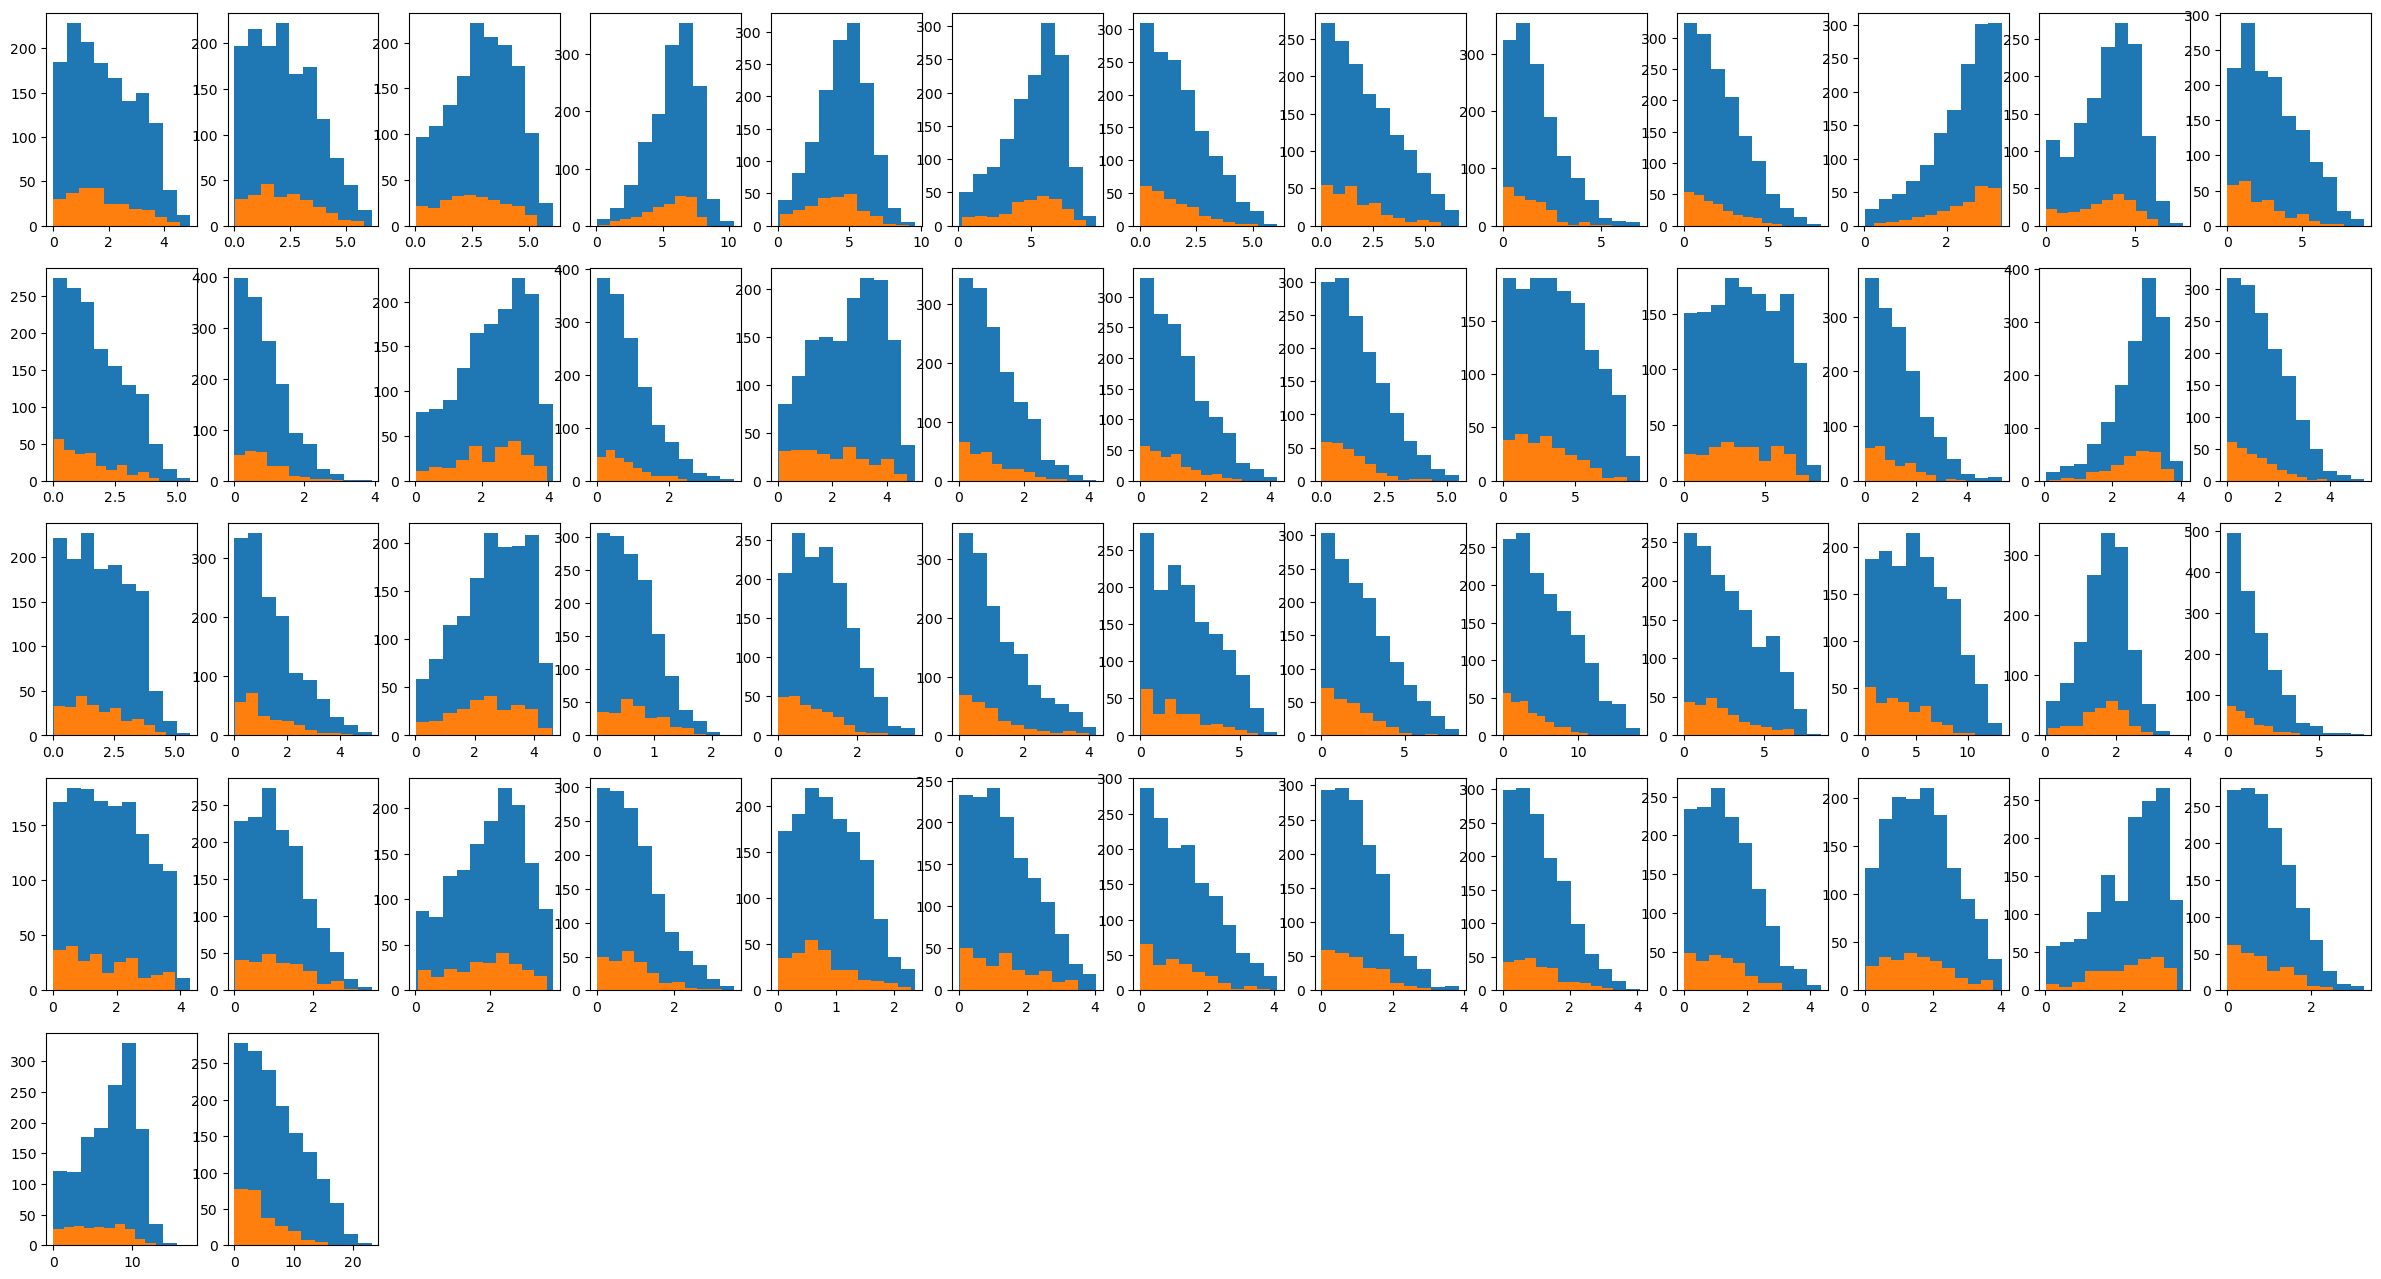

In [11]:
plt.figure(figsize=(30,16))
for i in range(54):
    plt.subplot(5,13,i+1)
    plt.hist(all_implausibilities_for_samples[:,i])
    plt.hist(all_implausibilities_for_samples[min_ix,i])

### select wave4 paramsets

In [19]:
# save the sample as csv (param values are still normalized)
wave4_sets = NROY_samples.iloc[min_ix].drop_duplicates(subset='jmaxb1').head(200)
wave4_sets.to_csv('../paramsets/wave4_paramsets.csv')

In [20]:
# save the sample as a netCDF (param values are still normalized)
default_params = xr.open_dataset(utils_dir+'/default_params_norm.nc')
param_ranges='/glade/u/home/linnia/CLM6-PPE/gen_ensembles/gen_paramfiles/clm6ppe_paramranges_10042025.csv'
paramset_csv = '../paramsets/wave4_paramsets.csv'
outfile = '../paramsets/wave4_paramsets.nc'
write_paramset_ds(default_params, param_ranges, paramset_csv, pft_param_names, outfile)

In [11]:
# two top up paramsets
wave4_sets = NROY_samples.iloc[min_ix].drop_duplicates(subset='jmaxb1')
wave4_sets.iloc[203:205].to_csv('../paramsets/wave4_paramsets_topup2.csv')

# save the sample as a netCDF (param values are still normalized)
default_params = xr.open_dataset(utils_dir+'/default_params_norm.nc')
param_ranges='/glade/u/home/linnia/CLM6-PPE/gen_ensembles/gen_paramfiles/clm6ppe_paramranges_10042025.csv'
paramset_csv = '../paramsets/wave4_paramsets_topup2.csv'
outfile = '../paramsets/wave4_paramsets_topup2.nc'
write_paramset_ds(default_params, param_ranges, paramset_csv, pft_param_names, outfile)

### Check

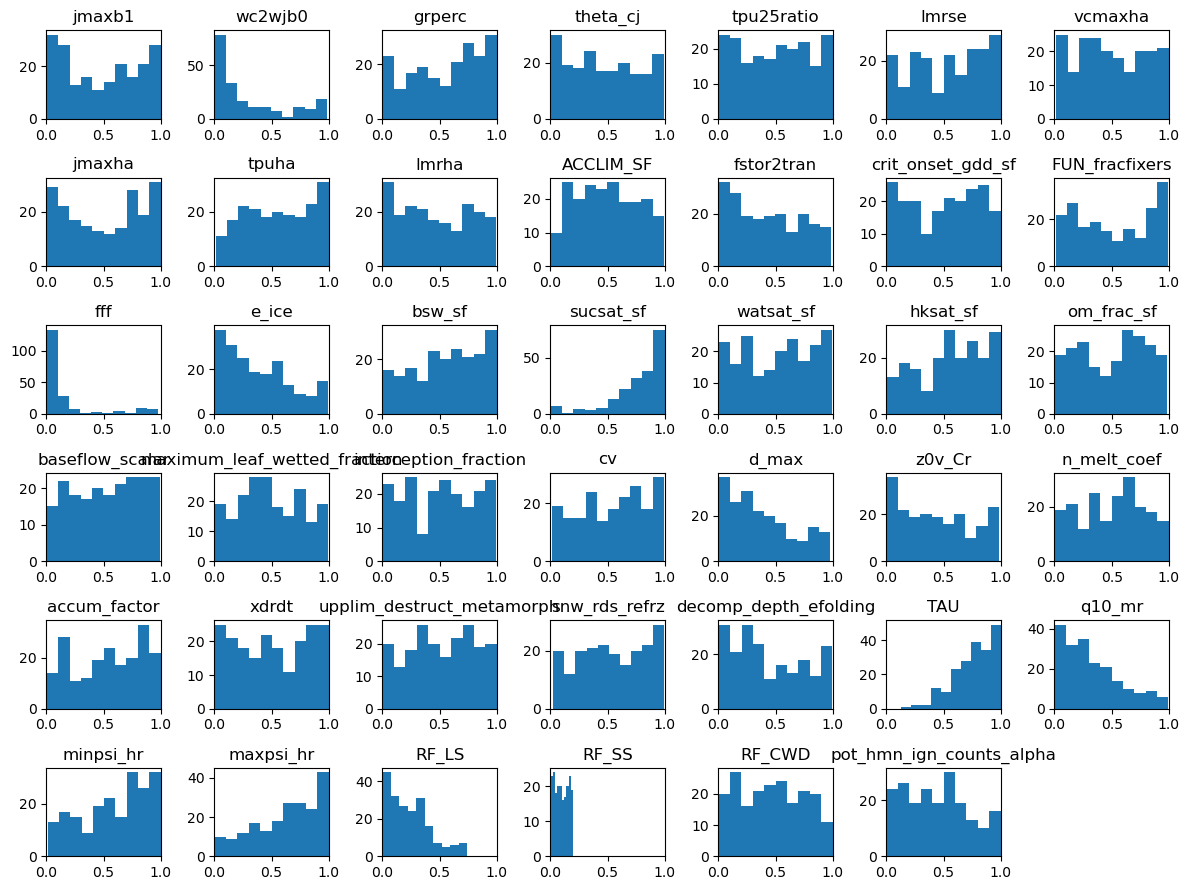

In [21]:
plt.figure(figsize=(12,9))
for i in range(len(universal_param_names)):
    plt.subplot(6,7,i+1)
    plt.hist(wave4_sets[universal_param_names[i]])
    plt.title(universal_param_names[i])
    plt.xlim([0,1])
plt.tight_layout()
plt.savefig('./figs/posteriors_uparams_wave4.png')

### Which biomes/variables are most constraining